## ML3: Engineer Features for Better Model Performance


In [4]:


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Automobile = pd.read_csv('Automobile_data.csv')



In [5]:
## Task 1: Identify Important Features for Vehicle Pricing

Automobile.corr(numeric_only=True)

,symboling,width,height,engine-size,city-mpg,highway-mpg,price
symboling,1.000000,-0.232919,-0.541038,-0.105790,-0.035823,0.034606,-0.085781
width,-0.232919,1.000000,0.279210,0.735433,-0.642704,-0.677218,0.718253
height,-0.541038,0.279210,1.000000,0.067149,-0.048640,-0.107358,0.132444
engine-size,-0.105790,0.735433,0.067149,1.000000,-0.653658,-0.677470,0.852995
city-mpg,-0.035823,-0.642704,-0.048640,-0.653658,1.000000,0.971337,-0.654611
highway-mpg,0.034606,-0.677218,-0.107358,-0.677470,0.971337,1.000000,-0.679048
price,-0.085781,0.718253,0.132444,0.852995,-0.654611,-0.679048,1.000000


In [6]:
Automobile_num=Automobile.select_dtypes(["int64","float64"])
Automobile_cat=Automobile.select_dtypes(object)

C:\Users\PRITESH AMBRE\AppData\Local\Temp\ipykernel_24136\2619490640.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  Automobile_cat=Automobile.select_dtypes(object)


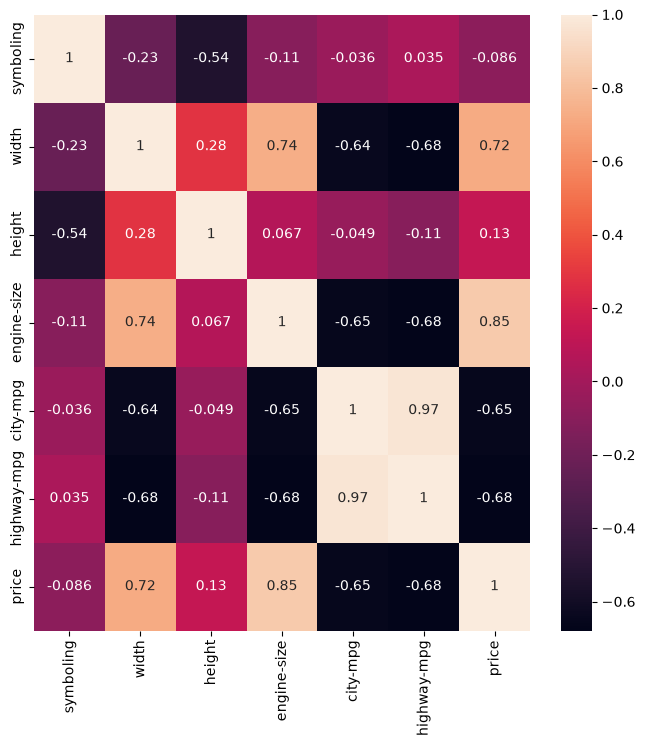

In [7]:
plt.figure(figsize=(8,8))
sns.heatmap(Automobile_num.corr(),annot=True)
plt.show()

## Task 2: Visualize Business Insights



In [8]:
## Integrated the new data variables

Automobile_new=pd.concat([Automobile_num,Automobile_cat],axis=1)

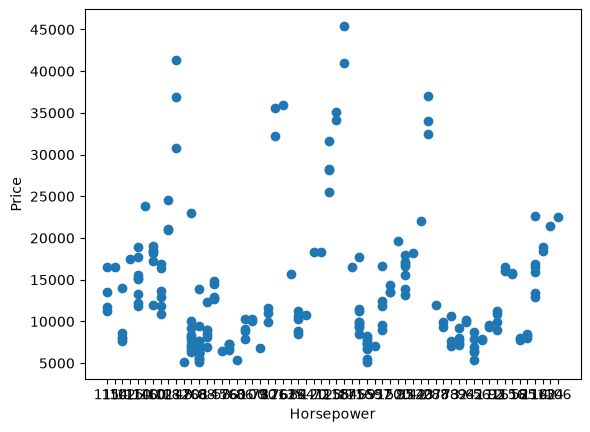

In [9]:
## Generate the Visualization for Horsepower vs Price

plt.scatter(Automobile_new['horsepower'], Automobile_new['price']) 
plt.xlabel("Horsepower")
plt.ylabel("Price") 
plt.show()

<Axes: xlabel='fuel-type', ylabel='price'>

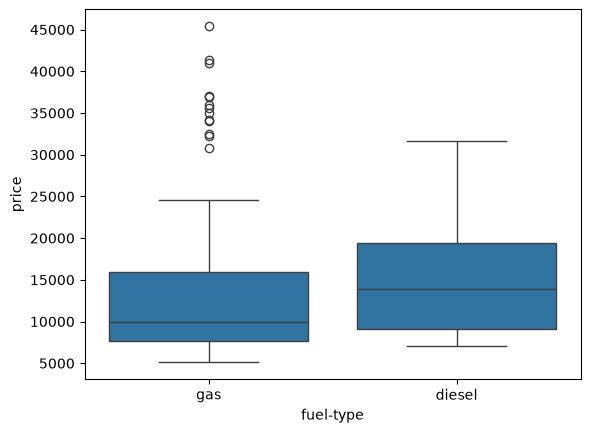

In [10]:
## Generate the Visualization for Fuel Type vs Price

sns.boxplot(x='fuel-type', y='price', data=Automobile_new)

## Task 3: Scale Features for Model Training



In [13]:
## Apply Min-Max Scaling

from sklearn.preprocessing import MinMaxScaler

for col in Automobile_num.columns:
    mx = MinMaxScaler()
    Automobile_new[col] = mx.fit_transform(Automobile_new[[col]])

In [ ]:
Automobile_std=Automobile_new.copy()
from sklearn.preprocessing import StandardScaler
ss = StandardScaler()
num_col = Automobile_std.select_dtypes(include='number').columns
Automobile_std[num_col] = ss.fit_transform(Automobile_std[num_col])

In [ ]:
## Create New Features

Automobile_new["area"]=Automobile_new["width"]*Automobile_new["height"]

In [21]:
## Verify

Automobile_new.head()

,symboling,width,height,engine-size,city-mpg,highway-mpg,price,normalized-losses,make,fuel-type,body-style,drive-wheels,engine-location,engine-type,horsepower,area
0,1.743470,-0.844782,-2.020417,0.074449,-0.646553,-0.546059,0.033935,?,alfa-romero,gas,convertible,rwd,front,dohc,111,1.706813
1,1.743470,-0.844782,-2.020417,0.074449,-0.646553,-0.546059,0.415118,?,alfa-romero,gas,convertible,rwd,front,dohc,111,1.706813
2,0.133509,-0.190566,-0.543527,0.604046,-0.953012,-0.691627,0.415118,?,alfa-romero,gas,hatchback,rwd,front,ohcv,154,0.103578
3,0.938490,0.136542,0.235942,-0.431076,-0.186865,-0.109354,0.091652,164,audi,gas,sedan,fwd,front,ohc,102,0.032216
4,0.938490,0.230001,0.235942,0.218885,-1.106241,-1.273900,0.535625,164,audi,gas,sedan,4wd,front,ohc,115,0.054267


In [29]:
Automobile_new.replace('?', np.nan, inplace=True)

corr_with_price = Automobile_new.corr(numeric_only=True)['price'].drop("price")

selection = pd.DataFrame({
    "correlation": corr_with_price.round(3),
    "Abs": corr_with_price.abs().round(3)
}).sort_values(by="Abs", ascending=False)

def decision(r):
    if pd.isna(r):
        return "No information (constant)"
    return "strong" if r > 0.70 else ("Moderate" if r >= 0.30 else "weak")

selection["Decision"] = selection["Abs"].apply(decision)

selection.drop(columns="Abs")

,correlation,Decision
engine-size,0.853,strong
width,0.718,strong
highway-mpg,-0.679,Moderate
city-mpg,-0.655,Moderate
area,0.166,weak
height,0.132,weak
symboling,-0.086,weak
